# Atividade da Aula 04


# Camada do Sistema Operacional (Linux)
## A. Fixar o Processo a um Núcleo Específico (CPU Affinity)
O escalonador do Linux pode mover seu processo entre diferentes núcleos, invalidando as caches L1 e L2. Use taskset para fixar a execução em um núcleo específico (ex: núcleo 2):

taskset -c 2 python src/execution_time.py

## B. Isolamento de Núcleos no Kernel (isolcpus)

Para garantir que nenhum outro processo do sistema execute no núcleo de teste:

    1. No arquivo de boot do GRUB (/etc/default/grub), adicione aos parâmetros do kernel:

    GRUB_CMDLINE_LINUX_DEFAULT="... isolcpus=2,3 nohz_full=2,3 rcu_nocbs=2,3"

    2. Execute o comando para atualizar o GRUB:
        sudo update-grub
    3. Reinicie o sistema.

    Agora os núcleos 2 e 3 não receberão tarefas do sistema, exceto quando você executá-las explicitamente com taskset -c 2.

## C. Prioridade do Processo e Escalonamento Real-Time
Execute o processo com prioridade máxima (nice) ou com uma política de escalonamento em tempo real (SCHED_FIFO via chrt):


### Executa com prioridade nice máxima (-20):
sudo nice -n -20 taskset -c 2 python src/execution_time.py
### Ou com escalonador FIFO de tempo real:
sudo chrt -f 99 taskset -c 2 python src/execution_time.py

In [ ]:
import os

# Fixa o processo do Jupyter Kernel no núcleo 2 (indexação começa em 0)
# Você pode passar um conjunto com um ou mais núcleos: {2} ou {2, 3}
os.sched_setaffinity(0, {2})

# Confirma em quais núcleos o processo está autorizado a rodar
nucleos_ativos = os.sched_getaffinity(0)
print(f"Kernel fixado para rodar no(s) núcleo(s): {nucleos_ativos}")

# 2. Warm-up (aquecimento de cache)
for _ in range(1000):
    _ = 1
    
# 3. Execução dos testes
# for n in lista_n:
#     gc.collect()
#     gc.disable()  # Desativa o GC durante a medição
#     try:
#         tic = time.perf_counter_ns()
        
#         for i in range(n):
#             x = 1
            
#         tac = time.perf_counter_ns()
#         duracao_s = (tac - tic) / 1e9
#         tempos.append(duracao_s)
#         print(f"n: {n:<8} | tempo: {duracao_s:.8f}s")
#     finally:
#         gc.enable()

Kernel fixado para rodar no(s) núcleo(s): {2}


# Preparando o ambiente
Para começar, preparei o ambiente deixando a máquina com configurações básicas para medir o tempo de execução:

- Modo Performance
- Desativar programas em segundo plano
- Modo avião ativado

obs: Já encontrei métodos ainda mais extremos para alcançar máx precisao, mas por ora nao sao necessarios.

# Listando as execucoes

As execucoes vao envolver as caracteristicas de Comparatividade e Operacionalidade:



## Operacionalidade

Calculo de expressões com os operadores ('+', '-', '*', '/', '%', '**', '//')

---

Por padrão as execucoes serao feitas com valores constantes, tendo como objetivo evitar operacoes de leitura e escrita, que podem interferir na medição do tempo de execução.

## Comparatividade

Funções if com os operadores ('==', '!=', '<', '>', '<=', '>=')

### ('==') igual

Before values
mean value: 2.9299259185791016e-05
standard_deviation: 1.3040842461803483e-06
coef_var: 0.04450912010815542

--------------------------------------------------------------------------------
After values
mean value: 2.895230832307235e-05
standard_deviation: 1.3752086433557424e-07
coef_var: 0.0047499101902691
--------------------------------------------------------------------------------


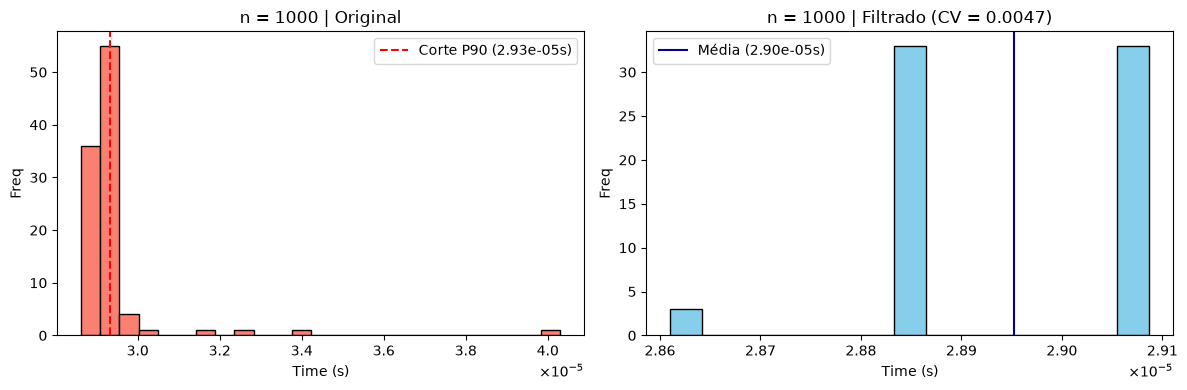

Before values
mean value: 0.0003246450424194336
standard_deviation: 3.234149950085246e-05
coef_var: 0.09962111005862216

--------------------------------------------------------------------------------
After values
mean value: 0.0003152185016208225
standard_deviation: 1.1217662571316378e-05
coef_var: 0.035586942116773795
--------------------------------------------------------------------------------


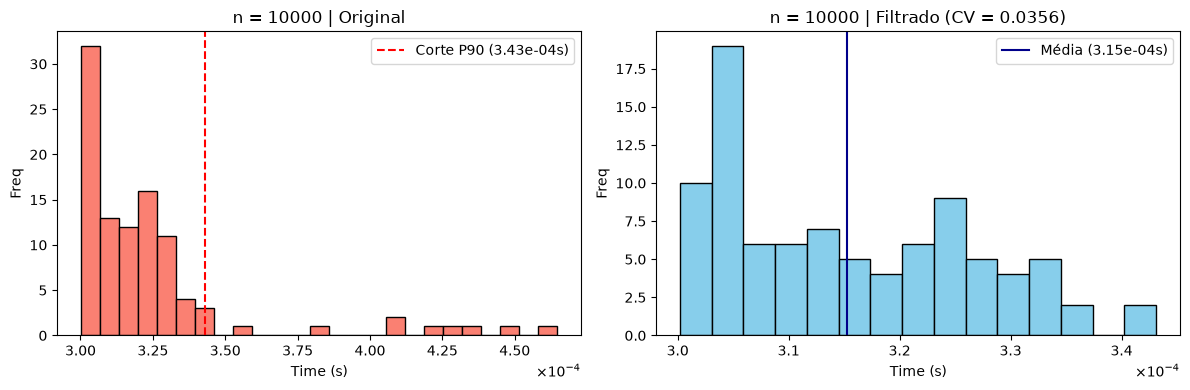

Before values
mean value: 0.003068859577178955
standard_deviation: 4.551215033974877e-05
coef_var: 0.014830313735497064

--------------------------------------------------------------------------------
After values
mean value: 0.0030554321077134873
standard_deviation: 9.168557184700321e-06
coef_var: 0.003000739948223412
--------------------------------------------------------------------------------


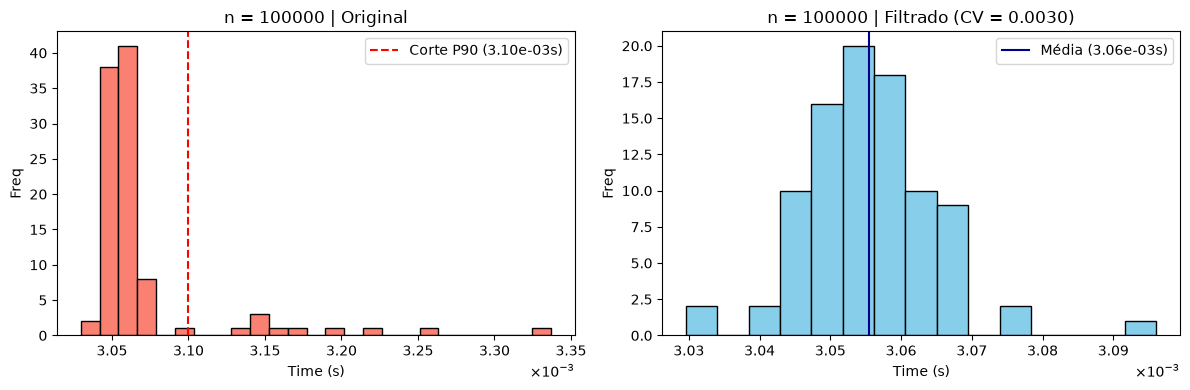

In [ ]:
import time
from matplotlib import pyplot as plt
import numpy as np

lista_n = [1000, 10000, 100000]
l = []
R = 100


for n in lista_n:
    tic = time()
    ll = []
    for i in range(R):
        tic = time()
        for i in range(n):
            if 1 == 1:
                True
        tac = time()
        ll.append(tac - tic)

    l.append(ll)

    before_array = np.array(ll)
    mean_before = np.mean(before_array)
    bfr_std_variation = np.std(before_array)
    bfr_coef_var = bfr_std_variation / mean_before

    aft_array = np.array(ll)
    l_corte = np.percentile(aft_array, 90)
    ll_filtrado = aft_array[aft_array < l_corte]

    mean_after = np.mean(ll_filtrado)
    aft_std_variation = np.std(ll_filtrado)
    aft_coef_var = aft_std_variation / mean_after

    print(f"Before values\nmean value: {mean_before}\nstandard_deviation: {bfr_std_variation}\ncoef_var: {bfr_coef_var}\n")
    print("--"*40)
    print(f"After values\nmean value: {mean_after}\nstandard_deviation: {aft_std_variation}\ncoef_var: {aft_coef_var}")
    print("--"*40)

    fig, axes = plt.subplots(1, 2, figsize=(12, 4))
    #cria um histograma com ciclos dos 3 valores na lista_n
    # plt.hist(ll,25)
    #elevo os valores de x a -4 so pra facilitar a visualizacao
    # plt.ticklabel_format(axis='x', style='sci', scilimits=(0, 0), useMathText=True)
    # plt.show()
    axes[0].hist(before_array, bins=25, edgecolor='black', color='salmon')
    axes[0].axvline(l_corte, color='red', linestyle='--', label=f'Corte P90 ({l_corte:.2e}s)')
    axes[0].set_title(f"n = {n} | Original")
    axes[0].set_xlabel("Time (s)")
    axes[0].set_ylabel("Freq")
    axes[0].ticklabel_format(axis='x', style='sci', scilimits=(0, 0), useMathText=True)
    axes[0].legend()

    axes[1].hist(ll_filtrado, bins=15, edgecolor='black', color='skyblue')
    axes[1].axvline(mean_after, color='darkblue', linestyle='-', label=f'Média ({mean_after:.2e}s)')
    axes[1].set_title(f"n = {n} | Filtrado (CV = {aft_coef_var:.4f})")
    axes[1].set_xlabel("Time (s)")
    axes[1].set_ylabel("Freq")
    axes[1].ticklabel_format(axis='x', style='sci', scilimits=(0, 0), useMathText=True)
    axes[1].legend()    

    plt.tight_layout()
    plt.show()

### (>) maior

Before values
mean value: 2.8755664825439453e-05
standard_deviation: 9.648708876116163e-07
coef_var: 0.03355411510979979

--------------------------------------------------------------------------------
After values
mean value: 2.849102020263672e-05
standard_deviation: 1.3674243323240385e-07
coef_var: 0.0047994923403883215
--------------------------------------------------------------------------------


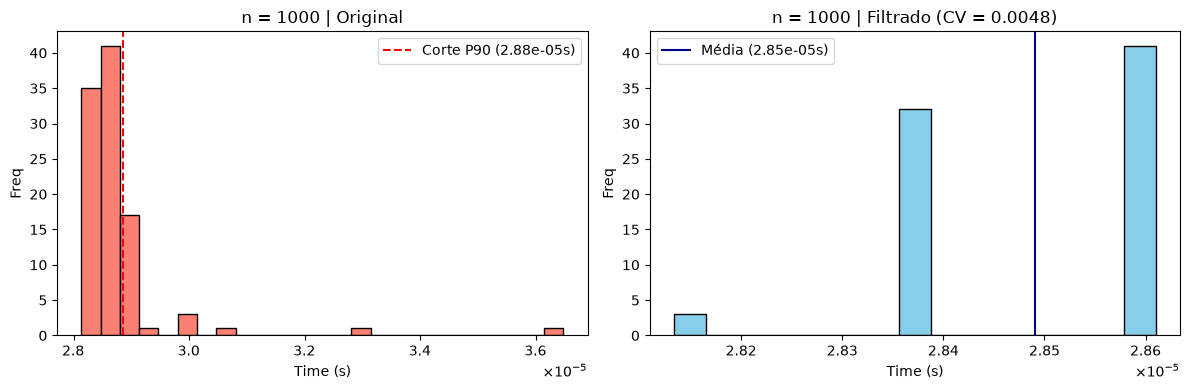

Before values
mean value: 0.0003182411193847656
standard_deviation: 3.8255670773523876e-05
coef_var: 0.12020970403661545

--------------------------------------------------------------------------------
After values
mean value: 0.0003078407711452908
standard_deviation: 1.5316487282241572e-05
coef_var: 0.049754576774408775
--------------------------------------------------------------------------------


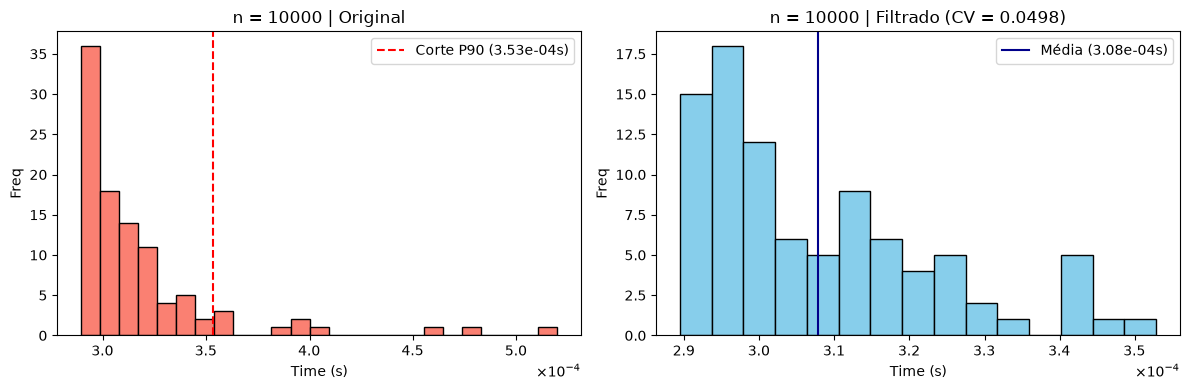

Before values
mean value: 0.0030935144424438475
standard_deviation: 0.00024527576659471955
coef_var: 0.07928709277366554

--------------------------------------------------------------------------------
After values
mean value: 0.0030237833658854165
standard_deviation: 0.00011877629799539608
coef_var: 0.03928069032174741
--------------------------------------------------------------------------------


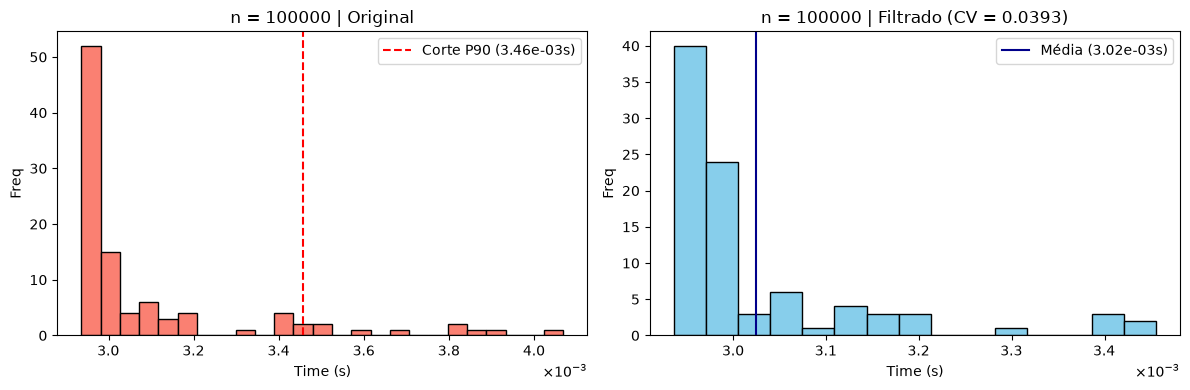

In [4]:
from time import time
from matplotlib import pyplot as plt
import numpy as np

lista_n = [1000, 10000, 100000]
l = []
R = 100

for n in lista_n:
    tic = time()
    ll = []
    for i in range(R):
        tic = time()
        for i in range(n):
            if 1 > 0:
                True
        tac = time()
        ll.append(tac - tic)

    l.append(ll)

    before_array = np.array(ll)
    mean_before = np.mean(before_array)
    bfr_std_variation = np.std(before_array)
    bfr_coef_var = bfr_std_variation / mean_before

    aft_array = np.array(ll)
    l_corte = np.percentile(aft_array, 90)
    ll_filtrado = aft_array[aft_array < l_corte]

    mean_after = np.mean(ll_filtrado)
    aft_std_variation = np.std(ll_filtrado)
    aft_coef_var = aft_std_variation / mean_after

    print(f"Before values\nmean value: {mean_before}\nstandard_deviation: {bfr_std_variation}\ncoef_var: {bfr_coef_var}\n")
    print("--"*40)
    print(f"After values\nmean value: {mean_after}\nstandard_deviation: {aft_std_variation}\ncoef_var: {aft_coef_var}")
    print("--"*40)

    fig, axes = plt.subplots(1, 2, figsize=(12, 4))
    #cria um histograma com ciclos dos 3 valores na lista_n
    # plt.hist(ll,25)
    #elevo os valores de x a -4 so pra facilitar a visualizacao
    # plt.ticklabel_format(axis='x', style='sci', scilimits=(0, 0), useMathText=True)
    # plt.show()
    axes[0].hist(before_array, bins=25, edgecolor='black', color='salmon')
    axes[0].axvline(l_corte, color='red', linestyle='--', label=f'Corte P90 ({l_corte:.2e}s)')
    axes[0].set_title(f"n = {n} | Original")
    axes[0].set_xlabel("Time (s)")
    axes[0].set_ylabel("Freq")
    axes[0].ticklabel_format(axis='x', style='sci', scilimits=(0, 0), useMathText=True)
    axes[0].legend()

    axes[1].hist(ll_filtrado, bins=15, edgecolor='black', color='skyblue')
    axes[1].axvline(mean_after, color='darkblue', linestyle='-', label=f'Média ({mean_after:.2e}s)')
    axes[1].set_title(f"n = {n} | Filtrado (CV = {aft_coef_var:.4f})")
    axes[1].set_xlabel("Time (s)")
    axes[1].set_ylabel("Freq")
    axes[1].ticklabel_format(axis='x', style='sci', scilimits=(0, 0), useMathText=True)
    axes[1].legend()    

    plt.tight_layout()
    plt.show()

### (>=) maior ou igual

### (>=) maior ou igual

### (>=) maior ou igual

### (>=) maior ou igual

### (<=) menor ou igual

Before values
mean value: 3.685712814331055e-05
standard_deviation: 1.5792314512102377e-05
coef_var: 0.42847382060527234

--------------------------------------------------------------------------------
After values
mean value: 3.4906777990869726e-05
standard_deviation: 1.9942771908989623e-07
coef_var: 0.005713151730648383
--------------------------------------------------------------------------------


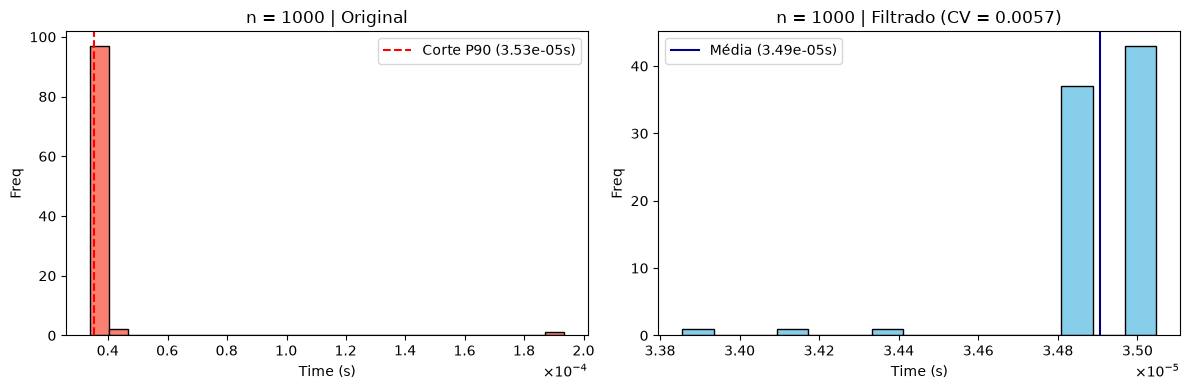

Before values
mean value: 0.00030153751373291016
standard_deviation: 1.6028880186419934e-05
coef_var: 0.053157167703576924

--------------------------------------------------------------------------------
After values
mean value: 0.0002978695763481988
standard_deviation: 7.619645518584269e-06
coef_var: 0.025580475898207132
--------------------------------------------------------------------------------


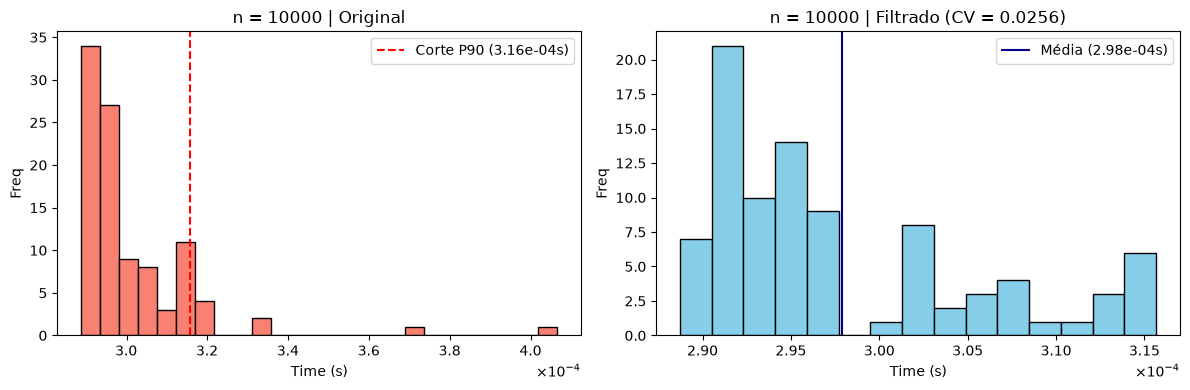

Before values
mean value: 0.0029862523078918457
standard_deviation: 8.753277890216157e-05
coef_var: 0.029311916702696703

--------------------------------------------------------------------------------
After values
mean value: 0.002959646119011773
standard_deviation: 3.552566900565754e-05
coef_var: 0.01200335025780703
--------------------------------------------------------------------------------


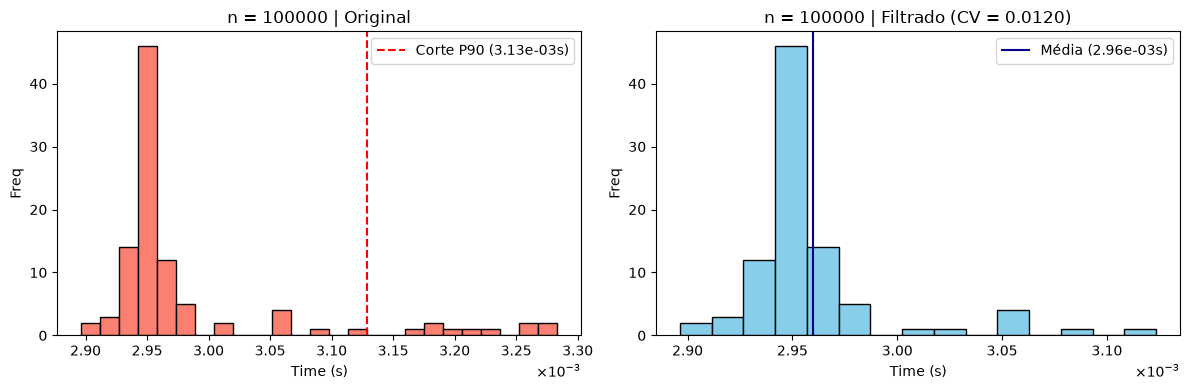

In [ ]:
from time import time
from matplotlib import pyplot as plt
import numpy as np

lista_n = [1000, 10000, 100000]
l = []
R = 100

for n in lista_n:
    tic = time()
    ll = []
    for i in range(R):
        tic = time()
        for i in range(n):
            if 1 >= 1:
                True
        tac = time()
        ll.append(tac - tic)

    l.append(ll)

    before_array = np.array(ll)
    mean_before = np.mean(before_array)
    bfr_std_variation = np.std(before_array)
    bfr_coef_var = bfr_std_variation / mean_before

    aft_array = np.array(ll)
    l_corte = np.percentile(aft_array, 90)
    ll_filtrado = aft_array[aft_array < l_corte]

    mean_after = np.mean(ll_filtrado)
    aft_std_variation = np.std(ll_filtrado)
    aft_coef_var = aft_std_variation / mean_after

    print(f"Before values\nmean value: {mean_before}\nstandard_deviation: {bfr_std_variation}\ncoef_var: {bfr_coef_var}\n")
    print("--"*40)
    print(f"After values\nmean value: {mean_after}\nstandard_deviation: {aft_std_variation}\ncoef_var: {aft_coef_var}")
    print("--"*40)

    fig, axes = plt.subplots(1, 2, figsize=(12, 4))
    #cria um histograma com ciclos dos 3 valores na lista_n
    # plt.hist(ll,25)
    #elevo os valores de x a -4 so pra facilitar a visualizacao
    # plt.ticklabel_format(axis='x', style='sci', scilimits=(0, 0), useMathText=True)
    # plt.show()
    axes[0].hist(before_array, bins=25, edgecolor='black', color='salmon')
    axes[0].axvline(l_corte, color='red', linestyle='--', label=f'Corte P90 ({l_corte:.2e}s)')
    axes[0].set_title(f"n = {n} | Original")
    axes[0].set_xlabel("Time (s)")
    axes[0].set_ylabel("Freq")
    axes[0].ticklabel_format(axis='x', style='sci', scilimits=(0, 0), useMathText=True)
    axes[0].legend()

    axes[1].hist(ll_filtrado, bins=15, edgecolor='black', color='skyblue')
    axes[1].axvline(mean_after, color='darkblue', linestyle='-', label=f'Média ({mean_after:.2e}s)')
    axes[1].set_title(f"n = {n} | Filtrado (CV = {aft_coef_var:.4f})")
    axes[1].set_xlabel("Time (s)")
    axes[1].set_ylabel("Freq")
    axes[1].ticklabel_format(axis='x', style='sci', scilimits=(0, 0), useMathText=True)
    axes[1].legend()    

    plt.tight_layout()
    plt.show()

Before values
mean value: 3.685712814331055e-05
standard_deviation: 1.5792314512102377e-05
coef_var: 0.42847382060527234

--------------------------------------------------------------------------------
After values
mean value: 3.4906777990869726e-05
standard_deviation: 1.9942771908989623e-07
coef_var: 0.005713151730648383
--------------------------------------------------------------------------------


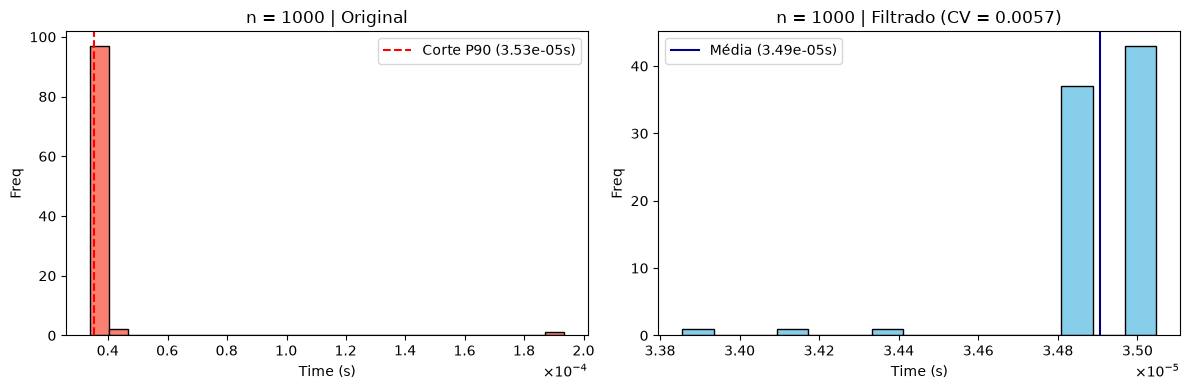

Before values
mean value: 0.00030153751373291016
standard_deviation: 1.6028880186419934e-05
coef_var: 0.053157167703576924

--------------------------------------------------------------------------------
After values
mean value: 0.0002978695763481988
standard_deviation: 7.619645518584269e-06
coef_var: 0.025580475898207132
--------------------------------------------------------------------------------


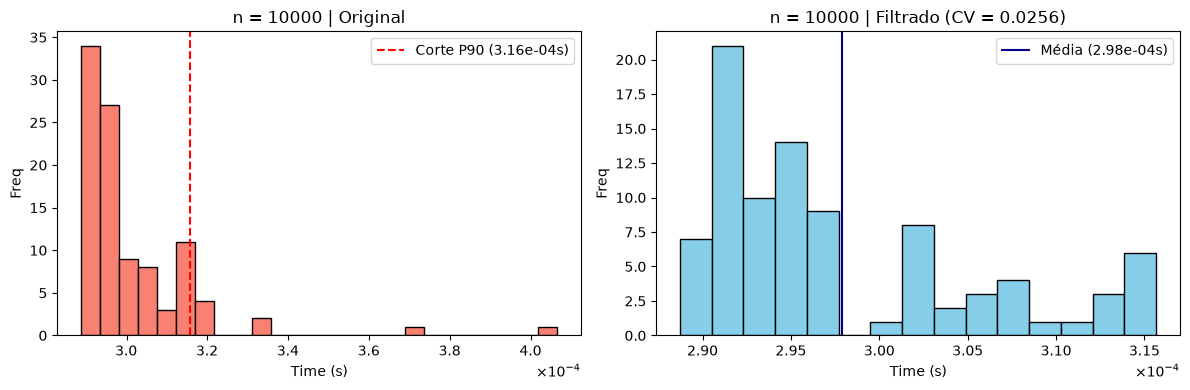

Before values
mean value: 0.0029862523078918457
standard_deviation: 8.753277890216157e-05
coef_var: 0.029311916702696703

--------------------------------------------------------------------------------
After values
mean value: 0.002959646119011773
standard_deviation: 3.552566900565754e-05
coef_var: 0.01200335025780703
--------------------------------------------------------------------------------


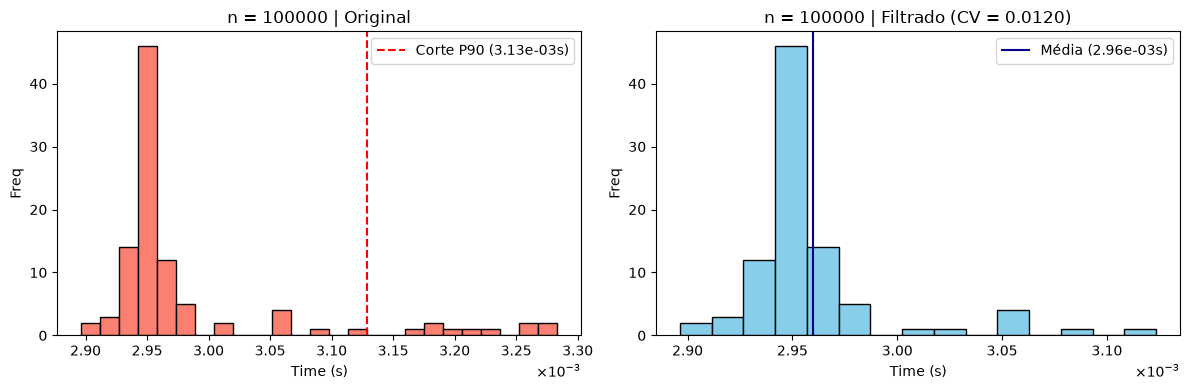

In [ ]:
from time import time
from matplotlib import pyplot as plt
import numpy as np

lista_n = [1000, 10000, 100000]
l = []
R = 100

for n in lista_n:
    tic = time()
    ll = []
    for i in range(R):
        tic = time()
        for i in range(n):
            if 1 >= 1:
                True
        tac = time()
        ll.append(tac - tic)

    l.append(ll)

    before_array = np.array(ll)
    mean_before = np.mean(before_array)
    bfr_std_variation = np.std(before_array)
    bfr_coef_var = bfr_std_variation / mean_before

    aft_array = np.array(ll)
    l_corte = np.percentile(aft_array, 90)
    ll_filtrado = aft_array[aft_array < l_corte]

    mean_after = np.mean(ll_filtrado)
    aft_std_variation = np.std(ll_filtrado)
    aft_coef_var = aft_std_variation / mean_after

    print(f"Before values\nmean value: {mean_before}\nstandard_deviation: {bfr_std_variation}\ncoef_var: {bfr_coef_var}\n")
    print("--"*40)
    print(f"After values\nmean value: {mean_after}\nstandard_deviation: {aft_std_variation}\ncoef_var: {aft_coef_var}")
    print("--"*40)

    fig, axes = plt.subplots(1, 2, figsize=(12, 4))
    #cria um histograma com ciclos dos 3 valores na lista_n
    # plt.hist(ll,25)
    #elevo os valores de x a -4 so pra facilitar a visualizacao
    # plt.ticklabel_format(axis='x', style='sci', scilimits=(0, 0), useMathText=True)
    # plt.show()
    axes[0].hist(before_array, bins=25, edgecolor='black', color='salmon')
    axes[0].axvline(l_corte, color='red', linestyle='--', label=f'Corte P90 ({l_corte:.2e}s)')
    axes[0].set_title(f"n = {n} | Original")
    axes[0].set_xlabel("Time (s)")
    axes[0].set_ylabel("Freq")
    axes[0].ticklabel_format(axis='x', style='sci', scilimits=(0, 0), useMathText=True)
    axes[0].legend()

    axes[1].hist(ll_filtrado, bins=15, edgecolor='black', color='skyblue')
    axes[1].axvline(mean_after, color='darkblue', linestyle='-', label=f'Média ({mean_after:.2e}s)')
    axes[1].set_title(f"n = {n} | Filtrado (CV = {aft_coef_var:.4f})")
    axes[1].set_xlabel("Time (s)")
    axes[1].set_ylabel("Freq")
    axes[1].ticklabel_format(axis='x', style='sci', scilimits=(0, 0), useMathText=True)
    axes[1].legend()    

    plt.tight_layout()
    plt.show()

Before values
mean value: 3.685712814331055e-05
standard_deviation: 1.5792314512102377e-05
coef_var: 0.42847382060527234

--------------------------------------------------------------------------------
After values
mean value: 3.4906777990869726e-05
standard_deviation: 1.9942771908989623e-07
coef_var: 0.005713151730648383
--------------------------------------------------------------------------------


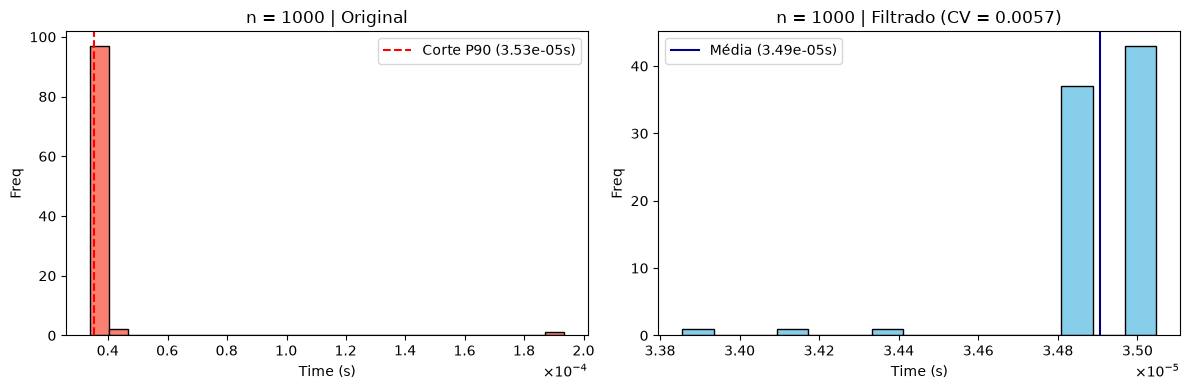

Before values
mean value: 0.00030153751373291016
standard_deviation: 1.6028880186419934e-05
coef_var: 0.053157167703576924

--------------------------------------------------------------------------------
After values
mean value: 0.0002978695763481988
standard_deviation: 7.619645518584269e-06
coef_var: 0.025580475898207132
--------------------------------------------------------------------------------


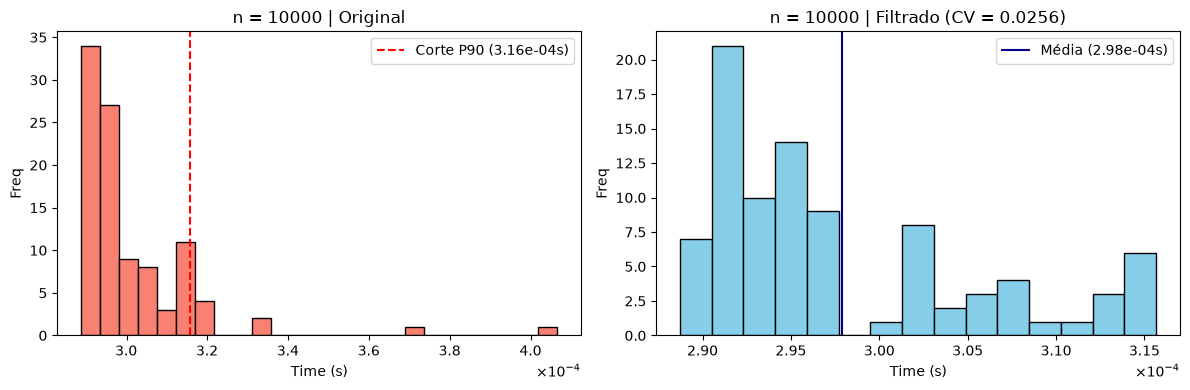

Before values
mean value: 0.0029862523078918457
standard_deviation: 8.753277890216157e-05
coef_var: 0.029311916702696703

--------------------------------------------------------------------------------
After values
mean value: 0.002959646119011773
standard_deviation: 3.552566900565754e-05
coef_var: 0.01200335025780703
--------------------------------------------------------------------------------


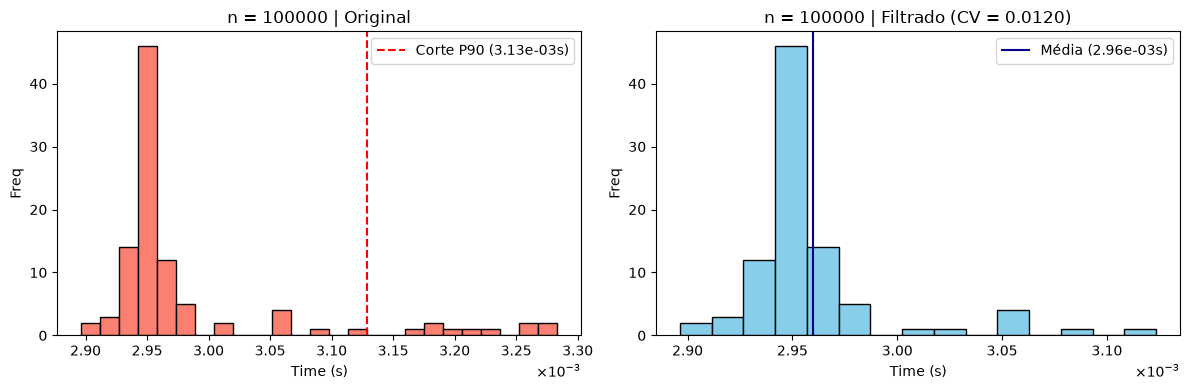

In [ ]:
from time import time
from matplotlib import pyplot as plt
import numpy as np

lista_n = [1000, 10000, 100000]
l = []
R = 100

for n in lista_n:
    tic = time()
    ll = []
    for i in range(R):
        tic = time()
        for i in range(n):
            if 1 >= 1:
                True
        tac = time()
        ll.append(tac - tic)

    l.append(ll)

    before_array = np.array(ll)
    mean_before = np.mean(before_array)
    bfr_std_variation = np.std(before_array)
    bfr_coef_var = bfr_std_variation / mean_before

    aft_array = np.array(ll)
    l_corte = np.percentile(aft_array, 90)
    ll_filtrado = aft_array[aft_array < l_corte]

    mean_after = np.mean(ll_filtrado)
    aft_std_variation = np.std(ll_filtrado)
    aft_coef_var = aft_std_variation / mean_after

    print(f"Before values\nmean value: {mean_before}\nstandard_deviation: {bfr_std_variation}\ncoef_var: {bfr_coef_var}\n")
    print("--"*40)
    print(f"After values\nmean value: {mean_after}\nstandard_deviation: {aft_std_variation}\ncoef_var: {aft_coef_var}")
    print("--"*40)

    fig, axes = plt.subplots(1, 2, figsize=(12, 4))
    #cria um histograma com ciclos dos 3 valores na lista_n
    # plt.hist(ll,25)
    #elevo os valores de x a -4 so pra facilitar a visualizacao
    # plt.ticklabel_format(axis='x', style='sci', scilimits=(0, 0), useMathText=True)
    # plt.show()
    axes[0].hist(before_array, bins=25, edgecolor='black', color='salmon')
    axes[0].axvline(l_corte, color='red', linestyle='--', label=f'Corte P90 ({l_corte:.2e}s)')
    axes[0].set_title(f"n = {n} | Original")
    axes[0].set_xlabel("Time (s)")
    axes[0].set_ylabel("Freq")
    axes[0].ticklabel_format(axis='x', style='sci', scilimits=(0, 0), useMathText=True)
    axes[0].legend()

    axes[1].hist(ll_filtrado, bins=15, edgecolor='black', color='skyblue')
    axes[1].axvline(mean_after, color='darkblue', linestyle='-', label=f'Média ({mean_after:.2e}s)')
    axes[1].set_title(f"n = {n} | Filtrado (CV = {aft_coef_var:.4f})")
    axes[1].set_xlabel("Time (s)")
    axes[1].set_ylabel("Freq")
    axes[1].ticklabel_format(axis='x', style='sci', scilimits=(0, 0), useMathText=True)
    axes[1].legend()    

    plt.tight_layout()
    plt.show()

Before values
mean value: 3.685712814331055e-05
standard_deviation: 1.5792314512102377e-05
coef_var: 0.42847382060527234

--------------------------------------------------------------------------------
After values
mean value: 3.4906777990869726e-05
standard_deviation: 1.9942771908989623e-07
coef_var: 0.005713151730648383
--------------------------------------------------------------------------------


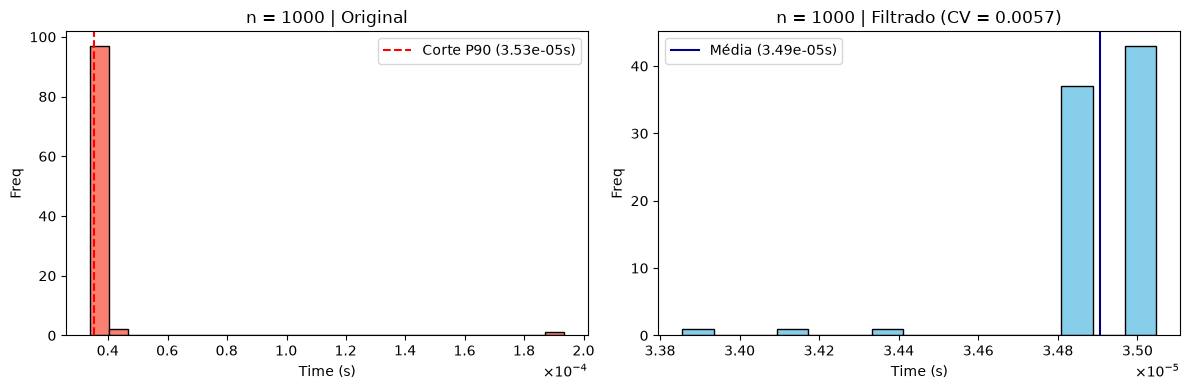

Before values
mean value: 0.00030153751373291016
standard_deviation: 1.6028880186419934e-05
coef_var: 0.053157167703576924

--------------------------------------------------------------------------------
After values
mean value: 0.0002978695763481988
standard_deviation: 7.619645518584269e-06
coef_var: 0.025580475898207132
--------------------------------------------------------------------------------


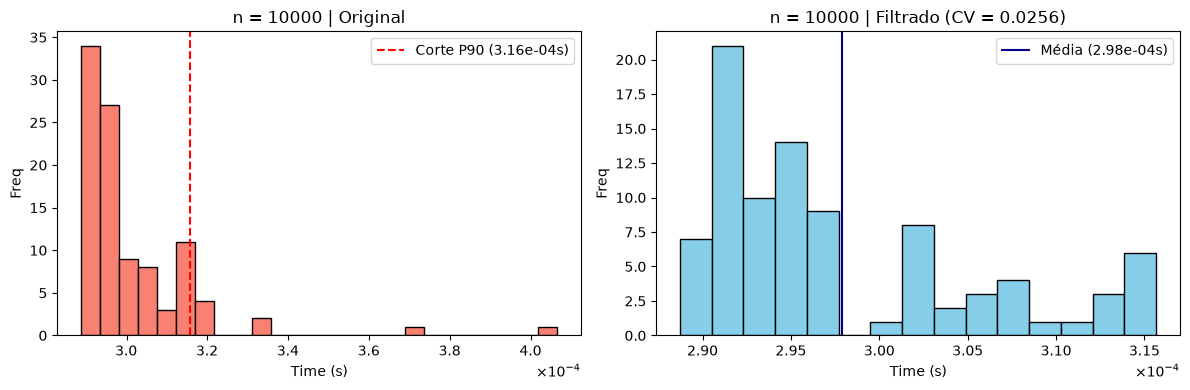

Before values
mean value: 0.0029862523078918457
standard_deviation: 8.753277890216157e-05
coef_var: 0.029311916702696703

--------------------------------------------------------------------------------
After values
mean value: 0.002959646119011773
standard_deviation: 3.552566900565754e-05
coef_var: 0.01200335025780703
--------------------------------------------------------------------------------


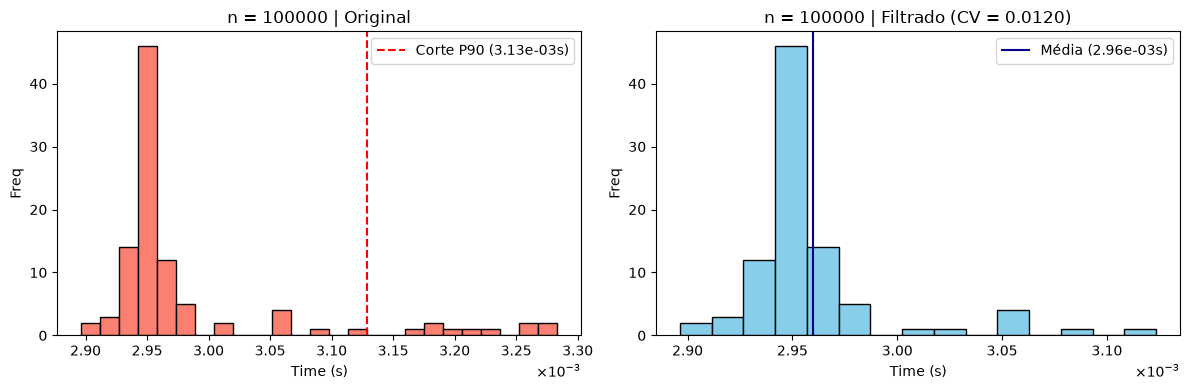

In [ ]:
from time import time
from matplotlib import pyplot as plt
import numpy as np

lista_n = [1000, 10000, 100000]
l = []
R = 100

for n in lista_n:
    tic = time()
    ll = []
    for i in range(R):
        tic = time()
        for i in range(n):
            if 1 >= 1:
                True
        tac = time()
        ll.append(tac - tic)

    l.append(ll)

    before_array = np.array(ll)
    mean_before = np.mean(before_array)
    bfr_std_variation = np.std(before_array)
    bfr_coef_var = bfr_std_variation / mean_before

    aft_array = np.array(ll)
    l_corte = np.percentile(aft_array, 90)
    ll_filtrado = aft_array[aft_array < l_corte]

    mean_after = np.mean(ll_filtrado)
    aft_std_variation = np.std(ll_filtrado)
    aft_coef_var = aft_std_variation / mean_after

    print(f"Before values\nmean value: {mean_before}\nstandard_deviation: {bfr_std_variation}\ncoef_var: {bfr_coef_var}\n")
    print("--"*40)
    print(f"After values\nmean value: {mean_after}\nstandard_deviation: {aft_std_variation}\ncoef_var: {aft_coef_var}")
    print("--"*40)

    fig, axes = plt.subplots(1, 2, figsize=(12, 4))
    #cria um histograma com ciclos dos 3 valores na lista_n
    # plt.hist(ll,25)
    #elevo os valores de x a -4 so pra facilitar a visualizacao
    # plt.ticklabel_format(axis='x', style='sci', scilimits=(0, 0), useMathText=True)
    # plt.show()
    axes[0].hist(before_array, bins=25, edgecolor='black', color='salmon')
    axes[0].axvline(l_corte, color='red', linestyle='--', label=f'Corte P90 ({l_corte:.2e}s)')
    axes[0].set_title(f"n = {n} | Original")
    axes[0].set_xlabel("Time (s)")
    axes[0].set_ylabel("Freq")
    axes[0].ticklabel_format(axis='x', style='sci', scilimits=(0, 0), useMathText=True)
    axes[0].legend()

    axes[1].hist(ll_filtrado, bins=15, edgecolor='black', color='skyblue')
    axes[1].axvline(mean_after, color='darkblue', linestyle='-', label=f'Média ({mean_after:.2e}s)')
    axes[1].set_title(f"n = {n} | Filtrado (CV = {aft_coef_var:.4f})")
    axes[1].set_xlabel("Time (s)")
    axes[1].set_ylabel("Freq")
    axes[1].ticklabel_format(axis='x', style='sci', scilimits=(0, 0), useMathText=True)
    axes[1].legend()    

    plt.tight_layout()
    plt.show()

Before values
mean value: 3.685712814331055e-05
standard_deviation: 1.5792314512102377e-05
coef_var: 0.42847382060527234

--------------------------------------------------------------------------------
After values
mean value: 3.4906777990869726e-05
standard_deviation: 1.9942771908989623e-07
coef_var: 0.005713151730648383
--------------------------------------------------------------------------------


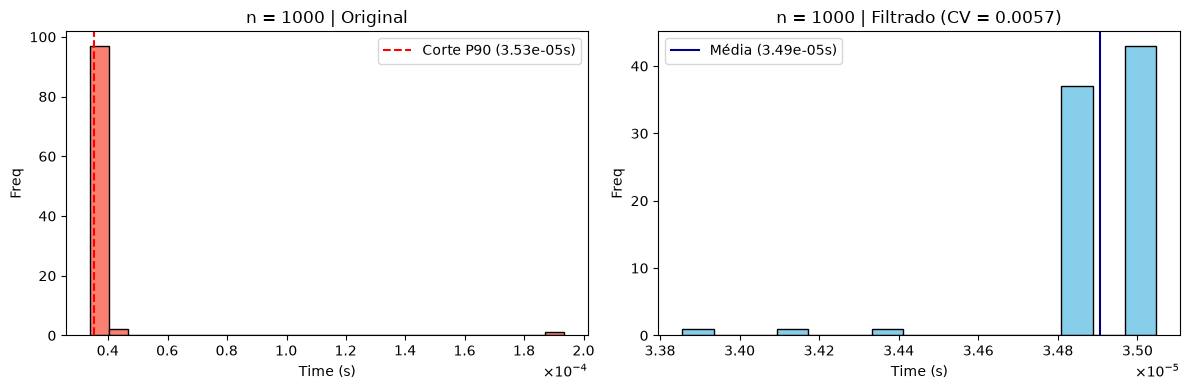

Before values
mean value: 0.00030153751373291016
standard_deviation: 1.6028880186419934e-05
coef_var: 0.053157167703576924

--------------------------------------------------------------------------------
After values
mean value: 0.0002978695763481988
standard_deviation: 7.619645518584269e-06
coef_var: 0.025580475898207132
--------------------------------------------------------------------------------


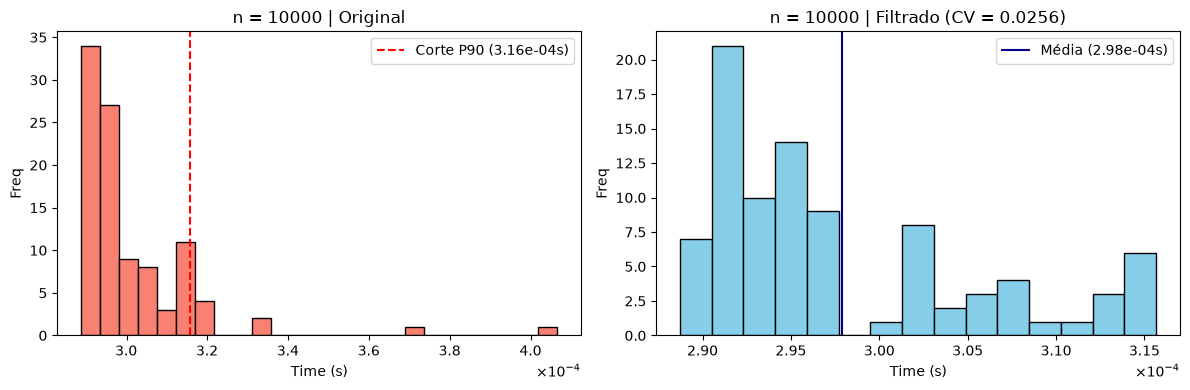

Before values
mean value: 0.0029862523078918457
standard_deviation: 8.753277890216157e-05
coef_var: 0.029311916702696703

--------------------------------------------------------------------------------
After values
mean value: 0.002959646119011773
standard_deviation: 3.552566900565754e-05
coef_var: 0.01200335025780703
--------------------------------------------------------------------------------


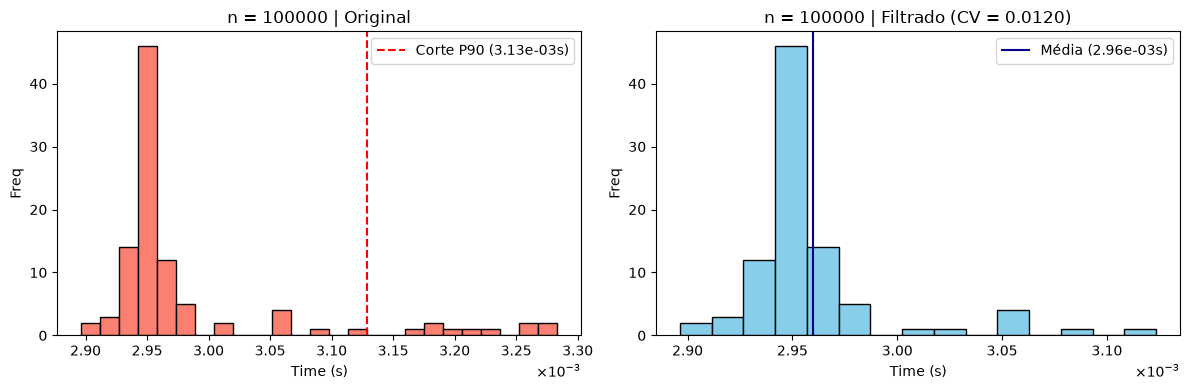

In [ ]:
from time import time
from matplotlib import pyplot as plt
import numpy as np

lista_n = [1000, 10000, 100000]
l = []
R = 100

for n in lista_n:
    tic = time()
    ll = []
    for i in range(R):
        tic = time()
        for i in range(n):
            if 1 >= 1:
                True
        tac = time()
        ll.append(tac - tic)

    l.append(ll)

    before_array = np.array(ll)
    mean_before = np.mean(before_array)
    bfr_std_variation = np.std(before_array)
    bfr_coef_var = bfr_std_variation / mean_before

    aft_array = np.array(ll)
    l_corte = np.percentile(aft_array, 90)
    ll_filtrado = aft_array[aft_array < l_corte]

    mean_after = np.mean(ll_filtrado)
    aft_std_variation = np.std(ll_filtrado)
    aft_coef_var = aft_std_variation / mean_after

    print(f"Before values\nmean value: {mean_before}\nstandard_deviation: {bfr_std_variation}\ncoef_var: {bfr_coef_var}\n")
    print("--"*40)
    print(f"After values\nmean value: {mean_after}\nstandard_deviation: {aft_std_variation}\ncoef_var: {aft_coef_var}")
    print("--"*40)

    fig, axes = plt.subplots(1, 2, figsize=(12, 4))
    #cria um histograma com ciclos dos 3 valores na lista_n
    # plt.hist(ll,25)
    #elevo os valores de x a -4 so pra facilitar a visualizacao
    # plt.ticklabel_format(axis='x', style='sci', scilimits=(0, 0), useMathText=True)
    # plt.show()
    axes[0].hist(before_array, bins=25, edgecolor='black', color='salmon')
    axes[0].axvline(l_corte, color='red', linestyle='--', label=f'Corte P90 ({l_corte:.2e}s)')
    axes[0].set_title(f"n = {n} | Original")
    axes[0].set_xlabel("Time (s)")
    axes[0].set_ylabel("Freq")
    axes[0].ticklabel_format(axis='x', style='sci', scilimits=(0, 0), useMathText=True)
    axes[0].legend()

    axes[1].hist(ll_filtrado, bins=15, edgecolor='black', color='skyblue')
    axes[1].axvline(mean_after, color='darkblue', linestyle='-', label=f'Média ({mean_after:.2e}s)')
    axes[1].set_title(f"n = {n} | Filtrado (CV = {aft_coef_var:.4f})")
    axes[1].set_xlabel("Time (s)")
    axes[1].set_ylabel("Freq")
    axes[1].ticklabel_format(axis='x', style='sci', scilimits=(0, 0), useMathText=True)
    axes[1].legend()    

    plt.tight_layout()
    plt.show()